# Module 13: Wednesday Session
## CS 5045: Computation for the Data Sciences
**Instructor:** Kurt Stein  
**Topic:** Web Data & APIs

Run cells in order. Pause at the **Pause and ask** prompts to invite student responses.

---
**Five operations in today's demo:**
- **Represent**: fetch JSON from Open-Meteo; save to file; load into DataFrame
- **Transform**: add a computed column (daily temperature range)
- **Communicate**: bar chart of temperature range over 7 days

---
## Setup
Import the libraries for this module.

In [26]:
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt

print('Libraries loaded.')

Libraries loaded.


---
## Section 1: Fetch and Save

The Open-Meteo URL for Blacksburg, VA:

    https://api.open-meteo.com/v1/forecast
      ?latitude=37.2296&longitude=-80.4139
      &daily=temperature_2m_max,temperature_2m_min,precipitation_sum
      &timezone=America/New_York

> **Pause and ask:** Before running this cell, predict:
> 1. What Python type will `data` be after `response.json()`? (list, dict, or str?)
> 2. What keys do you expect at the top level of the response?
> 3. What does a status code of 200 mean?
>
> Type your predictions in the chat.

In [27]:
# Cell 1: make the request, check the status code, save the response

URL = 'https://api.open-meteo.com/v1/forecast'
params = {
    'latitude':  37.2296,
    'longitude': -80.4139,
    'daily': 'temperature_2m_max,temperature_2m_min,precipitation_sum',
    'timezone': 'America/New_York',
}

response = requests.get(URL, params=params)

print(f'Status code: {response.status_code}')   # 200 = success

if response.status_code == 200:
    data = response.json()
    with open('weather_response.json', 'w') as f:
        json.dump(data, f, indent=2)
    print('Saved: weather_response.json')
else:
    raise SystemExit(f'Error: {response.status_code}')

Status code: 200
Saved: weather_response.json


---
## Section 2: Parse the JSON

This cell loads from the saved file, not from the live API.
It works even if Cell 1 was skipped on a slow network.

The Open-Meteo response has two levels:
- `data` is a dict. Its key `'daily'` holds the forecast.
- `data['daily']` is a **dict of parallel lists**: each key maps to a list of 7 values,
  one per forecast day. This is different from a list of dicts (the CSV row-by-row pattern).

In [28]:
# Cell 2: load from the saved file, navigate the JSON structure

with open('weather_response.json') as f:
    data = json.load(f)

print('Top-level keys:', list(data.keys()))

daily = data['daily']
print('Type of daily:    ', type(daily))
print('Keys inside daily:', list(daily.keys()))
print()
print('Dates:    ', daily['time'])
print('Max temps:', daily['temperature_2m_max'])
print()
print('First day, date:', daily['time'][0],
      ' max temp:', daily['temperature_2m_max'][0], 'C')

Top-level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
Type of daily:     <class 'dict'>
Keys inside daily: ['time', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum']

Dates:     ['2026-11-18', '2026-11-19', '2026-11-20', '2026-11-21', '2026-11-22', '2026-11-23', '2026-11-24']
Max temps: [15.4, 18.0, 18.3, 15.0, 15.8, 11.8, 4.9]

First day, date: 2026-11-18  max temp: 15.4 C


---
## Section 3: Build the DataFrame

> **Pause and ask:** If `data['daily']` is a dict of 4 parallel lists,
> each with 7 items, what will `pd.DataFrame(data['daily'])` look like?
> How many rows? How many columns? Where do the column names come from?
>
> Type your answer in the chat before we run the cell.

In [29]:
# Cell 3: convert the dict of parallel lists to a DataFrame

df = pd.DataFrame(daily)

print('Shape:', df.shape)   # expected: (7, 4)
print()
print(df.to_string(index=False))

Shape: (7, 4)

      time  temperature_2m_max  temperature_2m_min  precipitation_sum
2026-11-18                15.4                -0.7                0.0
2026-11-19                18.0                 3.4                0.0
2026-11-20                18.3                 2.9                0.0
2026-11-21                15.0                 3.1                0.0
2026-11-22                15.8                 3.6                0.0
2026-11-23                11.8                 2.1                0.0
2026-11-24                 4.9                -4.8                0.0


---
## Section 4: Add a Computed Column (Transform)

A **Transform** creates a new value from existing ones.
Here we compute the daily temperature range: the gap between
the high and the low for each day.

In [31]:
# Cell 4: add a computed column: temperature range (Transform)

df['temp_range'] = df['temperature_2m_max'] - df['temperature_2m_min']

cols = ['time', 'temperature_2m_max', 'temperature_2m_min', 'temp_range']
print('DataFrame with temperature range column:')
print(df[cols].to_string(index=False))
print()

max_range = df['temp_range'].max()
max_date  = df.loc[df['temp_range'].idxmax(), 'time']
print(f'Biggest daily spread: {max_range:.1f} C on {max_date}')

DataFrame with temperature range column:
      time  temperature_2m_max  temperature_2m_min  temp_range
2026-11-18                15.4                -0.7        16.1
2026-11-19                18.0                 3.4        14.6
2026-11-20                18.3                 2.9        15.4
2026-11-21                15.0                 3.1        11.9
2026-11-22                15.8                 3.6        12.2
2026-11-23                11.8                 2.1         9.7
2026-11-24                 4.9                -4.8         9.7

Biggest daily spread: 16.1 C on 2026-11-18


---
## Section 5: Visualize (Communicate)

> **Pause and ask:** What is one thing you would change about this chart
> to make it more useful for your audience?

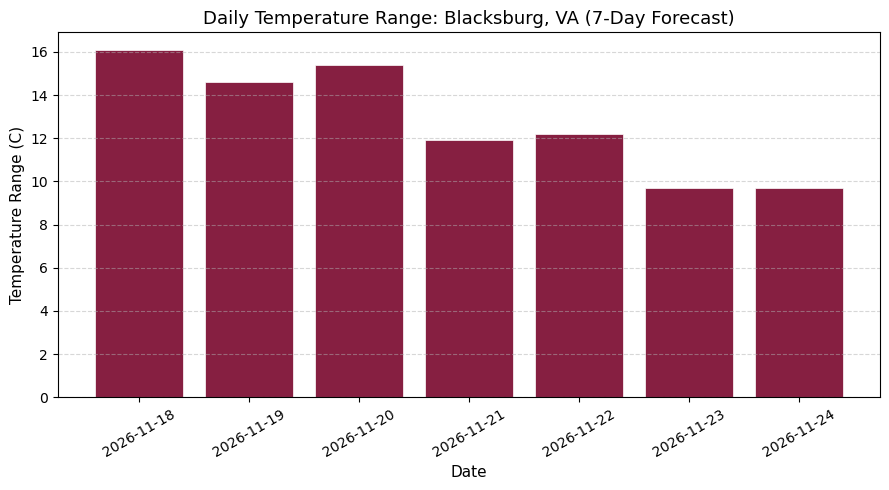

In [32]:
# Cell 5: bar chart of daily temperature range

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(df['time'], df['temp_range'],
       color='#861F41', edgecolor='white', linewidth=0.5)

ax.set_title('Daily Temperature Range: Blacksburg, VA (7-Day Forecast)',
             fontsize=13)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('Temperature Range (C)', fontsize=11)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## Connecting to the Assignment

The homework follows this exact pattern for a city of your choice:

1. **Section 1:** Fill in `MY_LAT`, `MY_LON`, `MY_TIMEZONE`. Run once with internet. Saves `weather_response.json`.
2. **Section 2:** Navigate the JSON: print keys, date list, first day's max temp.
3. **Section 3:** `df = pd.DataFrame(data['daily'])`, then print the shape and first 5 rows.
4. **Section 4:** Line plot of max and min temperature. Fill in column names, title, labels.
5. **Section 5:** Two written questions about your location's temperature range and why you chose it.
6. **Section 6:** Code from scratch. Load the fixed `sample_api_response.json` (Blacksburg), add a `temp_range` column like Cell 4 above, and compare dry days with wet days.
7. **Section 7:** Back to C. Change one threshold in a small sensor-feed program, recompile, and call it from Python with `subprocess`.

**Install requests if you have not already:**
```
pip install requests
```

**Timezone strings:** Use IANA format exactly: `'America/New_York'`, `'America/Chicago'`,
`'Europe/London'`. See the table in hw13.ipynb for common options.

**Questions?** Post in the Week 13 discussion or email KStein@VT.edu.